# Forest Fire Model - Ahmed Ismaiel

In [ ]:
import numpy as np
from numpy.polynomial.polynomial import polyfit
import matplotlib.pyplot as plt
from matplotlib.pyplot import draw,pause,close
import matplotlib
from scipy import ndimage
from scipy import spatial
from scipy.optimize import curve_fit

## Functions

### Model Rules & Functionality

In [2]:
def grow_tree(p, cells_arr):
    '''Checks for empty cells and returns an array of new trees in them according to the probability p'''
    
    # create an array of binomial values with the same shape as the grid (cells_arr) according to probability p 
    seed = np.random.binomial(1, p, (cells_arr.shape[0],cells_arr.shape[1]))

    # returns a boolean array with the same shape as cells_arr. each element [x,y] is 'True' if cell [x,y] in cells_arr 
    # is empty (0) and the corressponding element in the randomly generated array (seed) is equal to 1 and 'False' otherwise
    return (cells_arr == 0) & (seed==1)


def lightening(f, cells_arr):
    '''Strikes cells with trees in them with lightening with probability f'''
    # works in a similar way to grow_tree
    
    # create an array of binomial values with the same shape as the grid (cells_arr) according to probability f
    strike = np.random.binomial(1, f, (cells_arr.shape[0],cells_arr.shape[1]))
    
    # returns a boolean array with the same shape as cells_arr. each element [x,y] is 'True' if cell [x,y] in cells_arr is
    # a tree (1) and the corressponding element in the randomly generated array (strike) is equal to 1, and 'False' otherwise
    return (cells_arr == 1) & (strike==1)


def fire_spread(cells_arr):
    '''Checks whether any neighboring cells are on fire'''
    
    # create an array which wraps for periodic boundary conditions (flat topology to a donut)
    c_wrap = np.pad(cells_arr, pad_width=1, mode='wrap')
    
    # Find adjacent cells that are on fire (2)
    fire_adjacent = ((c_wrap[2:, 1:-1] == 2) |     # up    (x, y+1)
                     (c_wrap[:-2, 1:-1] == 2)|     # down  (x, y-1)
                     (c_wrap[1:-1, 2:] == 2) |     # left  (x-1, y)
                     (c_wrap[1:-1, :-2] == 2) )    # right (x+1, y)
    
    # returns a boolean array with the same shape as cells_arr. each element [x,y] is 'True' if cell [x,y] in cells_arr 
    # is a tree (1) and any of it's adjacent cells is on fire (2), and 'False' otherwise
    return (cells_arr == 1) & fire_adjacent
    
    
def new_grid(cells_arr, p, f):
    '''Updates the grid according to the pre-defined rules and probabilities'''
    
    # empty new grid
    cells_arr_new = np.zeros_like(cells_arr)
    
    # calling other functions
    g_trees = grow_tree(p,cells_arr)
    
    light = lightening(f,cells_arr)
    
    fire = fire_spread(cells_arr)
    
    # cells currently on fire
    ash = (cells_arr == 2)            
    
    # updating the states of the cells
    cells_arr_new[(cells_arr == 1) & (~fire)] = 1   # cells with trees in them and no neighbours on fire are kept as trees
    cells_arr_new[g_trees] = 1                      # growing trees in empty cells
    cells_arr_new[ash] = 0                          # cells on fire become empty
    cells_arr_new[(fire==1)|(light==1)] = 2         # tree cells with neighbours on fire or hit by lightening are set on fire
    
    # return the updated grid
    return cells_arr_new

### Graphs & Analysis

In [3]:
def relative_graph(plot_data, N, cells_arr):
    '''Plots the number cells of each state at each time step as a fraction of all cells'''
    # cells_arr is used instead of x_c and y_c to reduce the number of input  parameters
    fig = plt.figure()
    n_trees = np.zeros(N)     # number of trees
    n_fires = np.zeros(N)     # number of fires
    n_empty = np.zeros(N)     # number of empty cells

    for k in range(N):
        n_trees[k] = np.count_nonzero(plot_data[k]==1)/(cells_arr.shape[0]*cells_arr.shape[1])
        n_fires[k] = np.count_nonzero(plot_data[k]==2)/(cells_arr.shape[0]*cells_arr.shape[1])
        n_empty[k] = np.count_nonzero(plot_data[k]==0)/(cells_arr.shape[0]*cells_arr.shape[1])

    x = np.arange(0,N,1)

    plt.plot(x, n_trees,'g', label='Cells containing trees')
    plt.plot(x, n_fires,'r', label='Cells on fire')
    plt.plot(x, n_empty,'k', label='Empty cells')

    plt.xlabel('Time')
    plt.ylabel('Fraction of all cells')
    plt.legend()
    plt.title('Relative number of cells of each state')
    plt.show()
    
    
def graph_areas(plot_data, state, plot_range):
    '''Plots cluster area against frequency on a log-log graph'''
    
    # plot_range is the range of time stops to draw data from
    # counting cluster sizes at multiple time steps ensures sufficient data for a more accurate plot
    # plot_range must be chosen such that the system has already achieved equilibrium 
    
    c = np.array([], dtype='int')    # array containing all clusters but with extra zeros

    # find clusters and their areas at each time step and save it to c
    for k in plot_range:
        lw, num = ndimage.label(plot_data[k]==state)

        cluster_areas = ndimage.sum_labels(plot_data[k]==state, lw, index=np.arange(lw.max() + 1)).astype('int')

        c = np.concatenate((cluster_areas,c))

    # remove the zeros
    all_areas=c[~(c==0)]    # array containing all clusters

    # create arrays for frequency and size to plot
    count = np.zeros((np.max(all_areas)), dtype=int)
    x = np.arange(0, np.max(all_areas), 1)

    # counts clusters of each size
    for i in x:
        count[i] = np.count_nonzero((all_areas==i))
    
    clr = ['k','g','r']
    
    plt.figure(figsize=[6,5])

    plt.scatter(x, count, c=clr[state], label='N.ipynb_checkpoints\s)')
    
    plt.loglog()
    plt.title('Log-Log plot of cluster area against frequency')
    plt.xlabel('Cluster area / Unit cells')
    plt.ylabel('Frequency')

    plt.show()
    

def graph_areas_fit(plot_data, state, plot_range):
    '''Plots cluster area against frequency on a log-log graph and a line fit'''
    
    # plot_range is the range of time stops to draw data from
    # counting cluster sizes at multiple time steps ensures sufficient data for a more accurate plot
    # plot_range must be chosen such that the system has already achieved equilibrium 
    
    c = np.array([], dtype='int')    # array containing all clusters but with extra zeros

    # find clusters and their areas at each time step and save it to c
    for k in plot_range:
        lw, num = ndimage.label(plot_data[k]==state)

        cluster_areas = ndimage.sum_labels(plot_data[k]==state, lw, index=np.arange(lw.max() + 1)).astype('int')

        c = np.concatenate((cluster_areas,c))

    # remove the zeros
    all_areas=c[~(c==0)]    # array containing all clusters

    # create arrays for frequency and size to plot
    count = np.zeros((np.max(all_areas)), dtype=int)
    x = np.arange(0, np.max(all_areas), 1)

    # counts clusters of each size
    for i in x:
        count[i] = np.count_nonzero((all_areas==i))
    
    plt.figure(figsize=[6,5])
    clr = ['k','g','r']
    plt.scatter(x, count, c=clr[state], label='N(s)')

    x1 = x[~(count==0)]
    count1 = count[~(count==0)]
    b, m = polyfit(np.log10(x1), np.log10(count1), 1)
    plt.plot(x1, 10**b*x1**m, 'b', label='power-law fit')
    
    plt.loglog()
    plt.title('Log-Log plot of cluster area against frequency')
    plt.xlabel('Cluster area / Unit cells')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()
    return print(f'm = {m}, b = {b}')


def graph_circumference_fit(plot_data, state, n):
    '''Plots distribution of approximate cluster circumferences'''
    # the circumference of a cluster is approximated by finding the smallest circle that encloses the cluster and
    # computing its circumference
    
    c = []   # list containing all cluster centres

    lw, num = ndimage.label(plot_data[n]==state)
    
    # find the centre of each cluster
    cluster_centres = ndimage.center_of_mass(plot_data[n]==state, lw, index=np.arange(lw.max() + 1))
    c.append(cluster_centres)
    
    all_centres=np.array(np.rint(c[~(c==0)][1:]))    # array containing all cluster centres as integers and removes zeros
    
    circumferences = np.zeros(len(all_centres))      # array containing all circumferences
    
    for i in range(len(all_centres)):
        XA = all_centres[i:i+1]       # to avoid XA has to be 2-dimentional error
        
        # finds the distance between the centre and the furthest cell in the cluster from it
        max_distance = np.max(spatial.distance.cdist(XA, np.argwhere(lw == i + 1), metric='euclidean'))
        
        circumferences[i] = 2 * np.pi * max_distance
        
    circumferences = circumferences[~(circumferences==0)].astype('int')
    
    # create arrays for frequency and circumference to plot
    count = np.zeros((np.max(circumferences)), dtype=int)
    x = np.arange(0, np.max(circumferences), 1)

    # counts clusters of each size
    for i in x:
        count[i] = np.count_nonzero((circumferences==i))
    
    plt.figure(figsize=[6,5])
    clr = ['k','g','r']
    plt.scatter(x, count, c=clr[state], label='N(s)')

    x1 = x[~(count==0)]
    count1 = count[~(count==0)]
    b, m = polyfit(np.log10(x1), np.log10(count1), 1)
    plt.plot(x1, 10**b*x1**m, 'b', label='power-law fit')
    
    plt.loglog()
    plt.title('Log-Log plot of cluster circumference against frequency')
    plt.xlabel('Cluster circumference / Unit cells')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()
    return print(f'm = {m}, b = {b}')

def grid_n_cluster_map(plot_data, state, n):
    '''Create a heat map of clusters by area at time step n'''
    fig = plt.figure()

    lw, num = ndimage.label(plot_data[n]==state)

    cluster_areas0 = ndimage.sum_labels(plot_data[n]==state, lw, index=np.arange(lw.max() + 1)).astype('int')
    plot_clusters0 = cluster_areas0[lw]

    im3 = plt.imshow(plot_clusters0, origin='lower', interpolation='nearest')
    plt.colorbar()
    plt.show()
    

def mean_density(plot_data, state, N_range, cells_arr):
    '''Calculate the mean density of a given state over a range of time steps'''
    # N_range is the range of time steps over which the mean density of a given state is calculated
    # N_range[0] is the satrting point and N_range[1] is the end point
    
    n_trees = np.zeros(len(N_range))     # number of trees
    n_fires = np.zeros(len(N_range))     # number of fires
    n_empty = np.zeros(len(N_range))     # number of empty cells
    
    for k in N_range:
        n_trees[k-N_range[0]] = np.count_nonzero(plot_data[k]==1)/(cells_arr.shape[0]*cells_arr.shape[1])
        n_fires[k-N_range[0]] = np.count_nonzero(plot_data[k]==2)/(cells_arr.shape[0]*cells_arr.shape[1])
        n_empty[k-N_range[0]] = np.count_nonzero(plot_data[k]==0)/(cells_arr.shape[0]*cells_arr.shape[1])
        
    b = np.array([n_empty,n_trees,n_fires])  # Indeces of elements in b correspond to the states they represent
    s = ['empty', 'tree', 'fire']    
    return print(f'The mean density of {s[state]} cells is {np.mean(b[state])}') 




### Animations

In [4]:
def animate(plot_data, an_range, t):
    '''Creates an animation of the forest fire simulation'''
    
    # an_range is the range of time steps to animate
    # t is the time for which each time step in the animation is displayed
    %matplotlib tk
    fig = plt.figure()
    ax = fig.gca()

    cmap = matplotlib.colors.ListedColormap(['Black','Green','Red'])
    board_image = ax.imshow(plot_data[0],cmap=cmap,vmin=0,vmax=2,origin='lower')

    for k in an_range:
        board_image.set_data(plot_data[k])
        draw()
        pause(t)

    close()
    %matplotlib inline

## Simulation & Analysis

In [5]:
# Model parameters
x_c = np.arange(0, 301, 1)    # x coordinates
y_c = np.arange(0, 301, 1)    # y coordinates

p = 0.07       # probability of a tree growing in a given cell
f = 0.000007   # probability of lightening striking a given cell

In [6]:
# running the simulation

# create the grid with all the cells being empty
cells_arr = np.zeros((len(x_c), len(y_c)), dtype=int)

N = 1000                             # number of time steps
plot_data = []                       # create list to save the grid values at each step
plot_data.append(cells_arr.copy())   # save the initial state of the grid

for q in range(N):
    cells_arr = np.array(new_grid(cells_arr,p,f))  # update the grid each time step
    plot_data.append(cells_arr.copy())             # save the new state


### Equilibrium Check

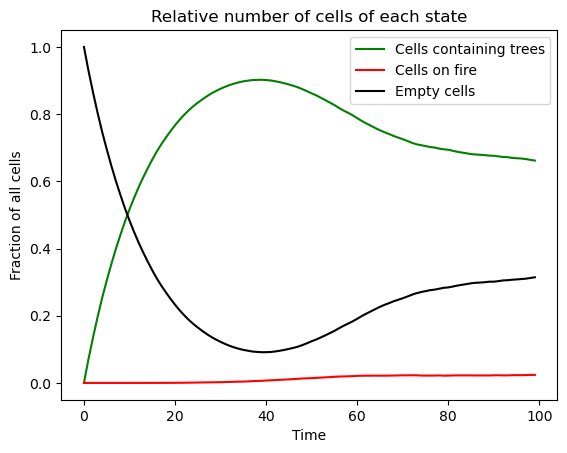

In [7]:
relative_graph(plot_data,N, cells_arr)

### Critical Behavior Check

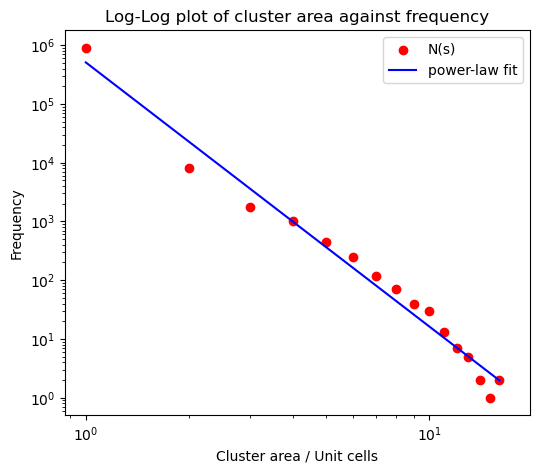

m = -4.4979518158076, b = 5.708271975423814


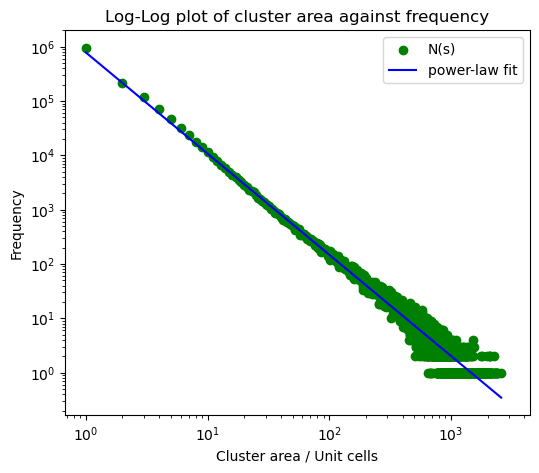

m = -1.8627820217105129, b = 5.895616220027715


In [9]:
graph_areas_fit(plot_data, 2, np.arange(401, 501, 1))
graph_areas_fit(plot_data, 1, np.arange(401, 501, 1))

### The Animation

In [9]:
animate(plot_data, range(N), 0.00001)

Exception in Tkinter callback
Traceback (most recent call last):
  File "C:\Users\ahmed\anaconda3\envs\main311\Lib\tkinter\__init__.py", line 1967, in __call__
    return self.func(*args)
           ^^^^^^^^^^^^^^^^
  File "C:\Users\ahmed\anaconda3\envs\main311\Lib\tkinter\__init__.py", line 861, in callit
    func(*args)
  File "C:\Users\ahmed\anaconda3\envs\main311\Lib\site-packages\matplotlib\backends\_backend_tk.py", line 302, in idle_draw
    self.draw()
  File "C:\Users\ahmed\anaconda3\envs\main311\Lib\site-packages\matplotlib\backends\backend_tkagg.py", line 10, in draw
    super().draw()
  File "C:\Users\ahmed\anaconda3\envs\main311\Lib\site-packages\matplotlib\backends\backend_agg.py", line 382, in draw
    self.figure.draw(self.renderer)
  File "C:\Users\ahmed\anaconda3\envs\main311\Lib\site-packages\matplotlib\artist.py", line 94, in draw_wrapper
    result = draw(artist, renderer, *args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ahmed\a

KeyboardInterrupt: 

### Critical Regime Analysis

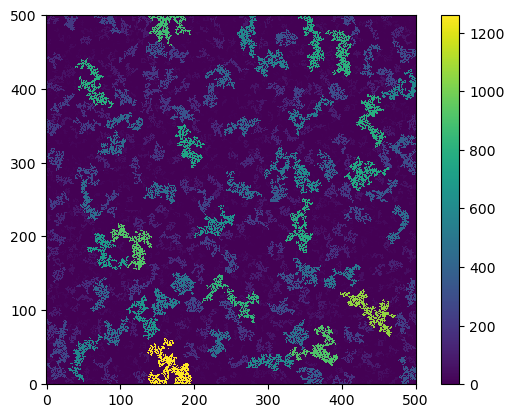

In [11]:
grid_n_cluster_map(plot_data,1,-1)

In [12]:
mean_density(plot_data, 1, np.arange(401, 501, 1), cells_arr)

The mean density of tree cells is 0.42287978932354847


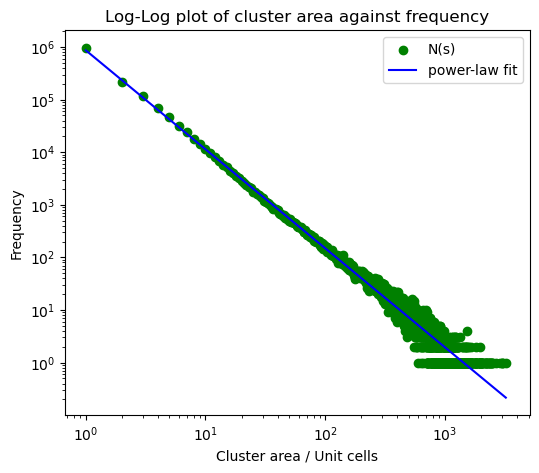

m = -1.8819164602761427, b = 5.937538973251317


In [13]:
graph_areas_fit(plot_data, 1, np.arange(401, 501, 1))

C:\Users\ahmed\anaconda3\envs\main311\Lib\site-packages\scipy\ndimage\_measurements.py:1550: RuntimeWarning: invalid value encountered in divide
  results = [sum_labels(input * grids[dir].astype(float), labels, index) / normalizer


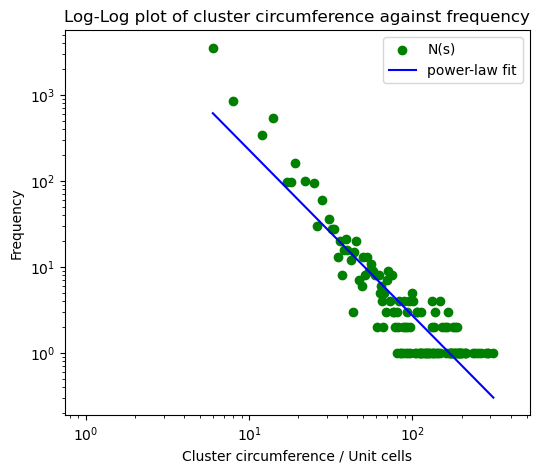

m = -1.9261277648929067, b = 4.288275153371191


In [19]:
graph_circumference_fit(plot_data, 1, -1)

## Test fire spread and periodic boundary conditions

In [ ]:
# test parameters
x_test = np.arange(0, 11, 1)    # x coordinates
y_test = np.arange(0, 11, 1)    # y coordinates

p_test = 0     # probability of a tree growing in a given cell
f_test = 0     # probability of lightening striking a given cell


In [18]:

# create the grid with all the cells being empty
cells_arr_test = np.ones((len(x_test), len(y_test)), dtype=int)
cells_arr_test[2,2]=2

N_test = 12                             # number of time steps
plot_data_test = []                     # create list to save the grid values at each step
plot_data_test.append(cells_arr_test.copy())  # save the initial state of the grid

for q in range(N_test):
    cells_arr_test = np.array(new_grid(cells_arr_test,p_test,f_test))  # update the grid each time step
    plot_data_test.append(cells_arr_test.copy())             # save the new state
    
animate(plot_data_test, range(N_test), 0.5)